<a href="https://colab.research.google.com/github/hmaroum-dotcom/Project_MLflow-iris-classification/blob/main/MLflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Étapes pour intégrer MLflow dans Google Colab**
1. Installer les dépendances nécessaires

Tout d'abord, installez les bibliothèques nécessaires, telles que MLflow, Scikit-learn, et Matplotlib (pour la visualisation des résultats) :

---



In [ ]:
!pip install mlflow scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.8/147.8 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 764.2/764.2 kB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 8.0 MB/s eta 0:00:00


2. Script MLflow pour Google Colab

Voici un script complet que vous pouvez exécuter sur Google Colab. Ce script utilise MLflow pour suivre l'expérimentation de l'entraînement d'un modèle RandomForest avec Scikit-learn.

2025/12/16 19:07:53 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2025/12/16 19:07:53 INFO mlflow.store.db.utils: Updating database tables
2025/12/16 19:07:53 INFO alembic.runtime.migration: Context impl SQLiteImpl.
2025/12/16 19:07:53 INFO alembic.runtime.migration: Will assume non-transactional DDL.
2025/12/16 19:07:53 INFO alembic.runtime.migration: Running upgrade  -> 451aebb31d03, add metric step
2025/12/16 19:07:53 INFO alembic.runtime.migration: Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
2025/12/16 19:07:53 INFO alembic.runtime.migration: Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
2025/12/16 19:07:53 INFO alembic.runtime.migration: Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
2025/12/16 19:07:53 INFO alembic.runtime.migration: Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
2025/12/16 19:07:53 INFO alembic.runtime.migration: Running 

Accuracy: 1.0


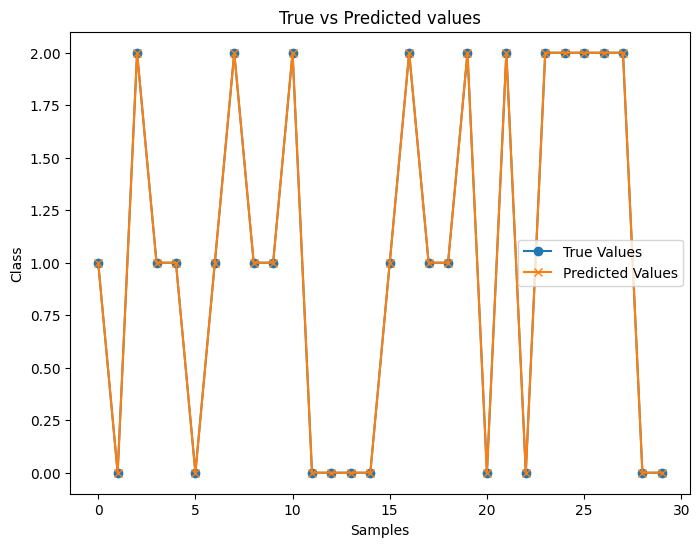

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Charger les données Iris
data = load_iris()
X = data.data
y = data.target

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialiser un essai dans MLflow
with mlflow.start_run():
    # Définir et entraîner un modèle
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Prédictions et évaluation
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    # Log des métriques
    mlflow.log_metric("accuracy", accuracy)

    # Log du modèle
    mlflow.sklearn.log_model(model, "random_forest_model")

    print(f"Accuracy: {accuracy}")

    # Visualiser les résultats
    plt.figure(figsize=(8, 6))
    plt.plot(y_test, label="True Values", marker='o')
    plt.plot(y_pred, label="Predicted Values", marker='x')
    plt.title("True vs Predicted values")
    plt.xlabel("Samples")
    plt.ylabel("Class")
    plt.legend()
    plt.show()

    # Enregistrer l'essai
    mlflow.end_run()

# Afficher les logs dans l'interface MLflow (cela peut être lancé localement, non directement dans Colab)
# !mlflow ui


In [ ]:
!mlflow ui

Traceback (most recent call last):
  File "/usr/local/bin/mlflow", line 5, in <module>
    from mlflow.cli import cli
  File "/usr/local/lib/python3.12/dist-packages/mlflow/__init__.py", line 44, in <module>
    from mlflow import (
  File "/usr/local/lib/python3.12/dist-packages/mlflow/artifacts/__init__.py", line 11, in <module>
    from mlflow.entities.file_info import FileInfo
  File "/usr/local/lib/python3.12/dist-packages/mlflow/entities/__init__.py", line 6, in <module>
    from mlflow.entities.assessment import (
  File "/usr/local/lib/python3.12/dist-packages/mlflow/entities/assessment.py", line 12, in <module>
    from mlflow.entities.assessment_error import AssessmentError
  File "/usr/local/lib/python3.12/dist-packages/mlflow/entities/assessment_error.py", line 4, in <module>
    from mlflow.protos.assessments_pb2 import AssessmentError as ProtoAssessmentError
  File "/usr/local/lib/python3.12/dist-packages/mlflow/protos/assessments_pb2.py", line 19, in <module>
    from . 

In [ ]:
!pip install mlflow pandas scikit-learn matplotlib

Aperçu des données:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


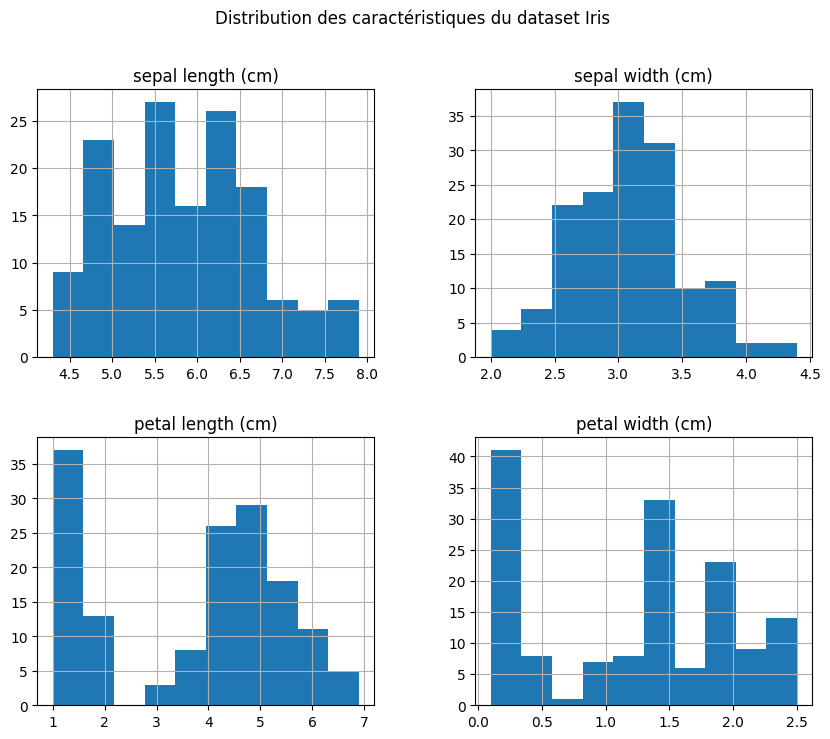

Précision du modèle : 1.0000


2025/12/11 19:27:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Le modèle a été logué avec succès dans MLflow.

Résultats de la prédiction:
     True Labels  Predictions
73             1            1
18             0            0
118            2            2
78             1            1
76             1            1
Les résultats de la prédiction ont été sauvegardés dans un fichier CSV: '/content/predictions.csv'.


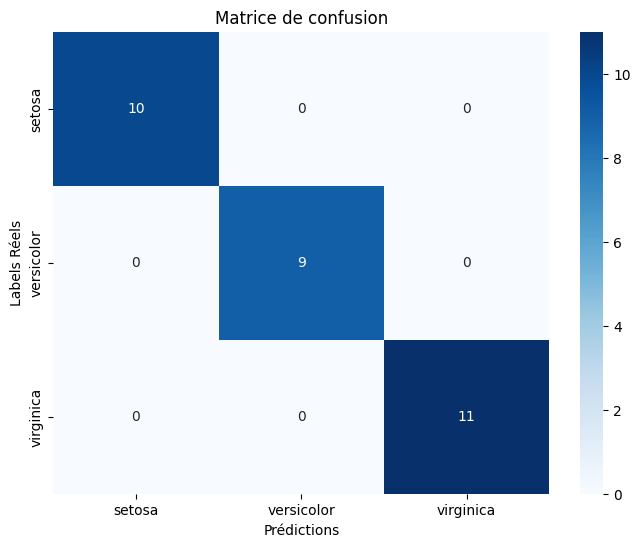

In [ ]:
import mlflow
import mlflow.sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# -----------------------
# 1. Charger et explorer les données
# -----------------------

# Charger le dataset Iris
data = load_iris()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Aperçu des premières lignes des données
print("Aperçu des données:")
print(df.head())

# Visualisation de la distribution des caractéristiques
df.drop('target', axis=1).hist(figsize=(10, 8))
plt.suptitle('Distribution des caractéristiques du dataset Iris')
plt.show()

# -----------------------
# 2. Préparation des données
# -----------------------

# Séparation des variables explicatives (X) et de la variable cible (y)
X = df.drop('target', axis=1)
y = df['target']

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------
# 3. Entraîner un modèle de machine learning (RandomForest)
# -----------------------

# Initialisation du modèle RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Entraînement du modèle
model.fit(X_train, y_train)

# Prédiction sur l'ensemble de test
y_pred = model.predict(X_test)

# Calcul de la précision du modèle
accuracy = accuracy_score(y_test, y_pred)
print(f"Précision du modèle : {accuracy:.4f}")

# -----------------------
# 4. Loguer le modèle et les métriques avec MLflow
# -----------------------

# Démarrer un essai MLflow
with mlflow.start_run():
    # Log des métriques (précision)
    mlflow.log_metric("accuracy", accuracy)

    # Log du modèle
    mlflow.sklearn.log_model(model, "random_forest_model")

    print("Le modèle a été logué avec succès dans MLflow.")

    # Fin de l'essai MLflow
    mlflow.end_run()

# -----------------------
# 5. Stocker les résultats de prédiction dans une Delta Table (simulée ici avec Pandas)
# -----------------------

# Créer un DataFrame avec les résultats de prédiction
predictions_df = pd.DataFrame({
    'True Labels': y_test,
    'Predictions': y_pred
})

# Afficher les premières lignes du DataFrame des prédictions
print("\nRésultats de la prédiction:")
print(predictions_df.head())

# Simuler une Delta Table avec un DataFrame Pandas (sur Colab, on utilise Pandas comme substitut)
# Enregistrement dans une table de données (ici, simplement une CSV pour la démonstration)
predictions_df.to_csv("/content/predictions.csv", index=False)

print("Les résultats de la prédiction ont été sauvegardés dans un fichier CSV: '/content/predictions.csv'.")

# -----------------------
# 6. Visualisation des résultats
# -----------------------

# Visualiser la matrice de confusion
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Labels Réels")
plt.show()

